# 01 · Fuentes y mundo

**Fase CRISP-DM:** 2. Entendimiento de los datos

**Objetivo:** construir el *mundo* de la simulación con datos **reales** de la Ciudad de México: qué restaurantes existen, de qué cocina son y dónde vive la gente.

| Entradas (`data/raw/`) | Salidas (`data/interim/world/`) |
|---|---|
| DENUE 2025 (INEGI), Censo 2020 por AGEB, Marco Geoestadístico 2020 | `restaurants_universe.parquet`, `restaurants.parquet`, `ageb.parquet`, mapa en `reports/figures/` |

> Este notebook solo narra el algoritmo. La lógica vive en `src/puzzle_recsys` y está cubierta por tests.

## Configuración
Toda decisión numérica (universo, tamaño de muestra, parámetros del KNN) vive en `config/simulation.yaml`. La semilla hace la corrida reproducible.

In [1]:
import numpy as np
import pandas as pd

from puzzle_recsys.catalog.cuisine_imputation import (
    CuisineRules,
    classify_by_rules,
    evaluate_knn_holdout,
    impute_cuisine_knn,
)
from puzzle_recsys.config import load_paths, load_simulation
from puzzle_recsys.eda.plots import plot_world
from puzzle_recsys.simulation.distributions import make_rng
from puzzle_recsys.simulation.world import build_restaurants, join_population
from puzzle_recsys.sources.denue import read_denue, select_restaurants
from puzzle_recsys.sources.download import download_source
from puzzle_recsys.sources.inegi import read_ageb_polygons, read_ageb_population

paths, sim = load_paths(), load_simulation()
world_cfg, knn_cfg = sim.world, sim.world["cuisine_knn"]
rng = make_rng(sim.seed, "world")  # flujo aleatorio propio de esta etapa
out_dir = paths.interim / "world"
out_dir.mkdir(parents=True, exist_ok=True)
print(f"Zona: {sim.metro_area} · semilla: {sim.seed} · restaurantes: {sim.scale.n_restaurants}")

Zona: CDMX · semilla: 20261116 · restaurantes: 1500


## 1. Descarga de fuentes

Las URLs están en `config/sources.yaml`. La descarga es **idempotente** (no repite lo que ya existe) y **valida el contenido**: el servidor del INEGI responde `Content-Type: text/html` aunque entregue un ZIP, así que se verifica la firma del archivo (`PK`) en lugar del encabezado.

In [2]:
raw_files = {name: download_source(name) for name in ("denue", "census_ageb", "marco_geo")}
pd.Series({k: f"{v.stat().st_size / 1e6:.1f} MB" for k, v in raw_files.items()}, name="tamaño")

denue          45.4 MB
census_ageb    13.0 MB
marco_geo      83.2 MB
Name: tamaño, dtype: str

## 2. Universo de restaurantes (DENUE)

El DENUE incluye todo el SCIAN 7225 (servicios de preparación de alimentos), desde restaurantes hasta puestos. **No todos son clientes posibles de Puzzle**, que necesita mesas y meseros. Criterio (configurable):

- **SCIAN incluidos:** 722511–722515 y 722517 (servicio en mesa o cafetería). Excluidos: autoservicio (722516), para llevar (722518) y otros (722519).
- **Tamaño:** 6 o más personas ocupadas, como *proxy* de "tiene meseros y mesas".

In [3]:
denue = read_denue(raw_files["denue"])
food = denue[denue["codigo_act"].str.startswith("7225")]
(
    food.groupby(["codigo_act", "nombre_act"])
    .size()
    .rename("establecimientos")
    .reset_index()
    .assign(incluido=lambda d: d["codigo_act"].isin(world_cfg["include_scian"]))
)

,codigo_act,nombre_act,establecimientos,incluido
0,722511,Restaurantes con servicio de preparación de al...,7781,True
1,722512,Restaurantes con servicio de preparación de pe...,1731,True
2,722513,Restaurantes con servicio de preparación de an...,9550,True
3,722514,Restaurantes con servicio de preparación de ta...,10295,True
4,722515,"Cafeterías, fuentes de sodas, neverías, refres...",9860,True
5,722516,Restaurantes de autoservicio,1648,False
6,722517,Restaurantes con servicio de preparación de pi...,3822,True
7,722518,Restaurantes que preparan otro tipo de aliment...,7400,False
8,722519,Servicios de preparación de otros alimentos pa...,3666,False


In [4]:
universe = select_restaurants(
    denue, include_scian=world_cfg["include_scian"], min_staff_band=world_cfg["min_staff_band"]
)
print(f"SCIAN 7225 en CDMX: {len(food):,} → universo de clientes posibles: {len(universe):,}")
universe.groupby("alcaldia").size().sort_values(ascending=False).rename("restaurantes").to_frame().T

SCIAN 7225 en CDMX: 55,753 → universo de clientes posibles: 8,175


alcaldia,Cuauhtémoc,Benito Juárez,Miguel Hidalgo,Iztapalapa,Coyoacán,Gustavo A. Madero,Álvaro Obregón,Tlalpan,Venustiano Carranza,Azcapotzalco,Cuajimalpa de Morelos,Iztacalco,Tláhuac,La Magdalena Contreras,Xochimilco,Milpa Alta
restaurantes,1994,953,854,662,647,639,585,424,369,297,208,181,117,103,102,40


## 3. Homologación de la cocina: reglas

El SCIAN solo distingue algunos tipos. Para el resto se usan **reglas sobre el nombre** (`data/external/cuisine_rules.yaml`): expresiones regulares sobre el nombre normalizado, evaluadas en orden (las específicas primero). Si el nombre no dice nada, se usa el valor por defecto del SCIAN.

In [5]:
rules = CuisineRules.from_yaml(paths.external / "cuisine_rules.yaml")
universe = universe.join(classify_by_rules(universe["name"], universe["scian_code"], rules))
universe["rule_source"].value_counts(dropna=False).rename("origen de la etiqueta").to_frame().T

rule_source,NAME,NaN,SCIAN
origen de la etiqueta,4112,2332,1731


## 4. Homologación de la cocina: KNN

Los restaurantes **sin etiqueta** se imputan con **K vecinos más cercanos** sobre n-gramas de caracteres del nombre y el código SCIAN. Tres decisiones de diseño:

1. **Se quita la palabra clave** del nombre antes de calcular las variables (`masked_name`). Si no, el KNN aprendería a "leer la palabra" y en los casos reales (que no la tienen) fallaría.
2. **Las etiquetas de marca no se transfieren** (`familiar_cadena`: Vips, Toks, Sanborns…). Un restaurante sin marca no "se parece" a una cadena.
3. **Sin ubicación** (`geo_weight = 0`): el experimento de abajo muestra que la ubicación empeora la imputación; la cocina no depende del barrio.

**Evaluación honesta:** se ocultan etiquetas que vinieron del nombre y se mide si el KNN las recupera, contra una línea base que predice siempre la clase más frecuente.

In [6]:
knn_kwargs = dict(
    n_neighbors=knn_cfg["n_neighbors"],
    min_confidence=knn_cfg["min_confidence"],
    default=knn_cfg["default_cuisine"],
    min_df=knn_cfg["min_df"],
    exclude_from_training=rules.non_transferable,
)
experiment = {
    f"geo_weight={w}": evaluate_knn_holdout(
        universe,
        holdout_fraction=knn_cfg["holdout_fraction"],
        rng=make_rng(sim.seed, "cuisine_knn_eval"),
        geo_weight=w,
        **knn_kwargs,
    )
    for w in (0.0, 1.0, 3.0)
}
pd.DataFrame(experiment).round(3)

,geo_weight=0.0,geo_weight=1.0,geo_weight=3.0
n_holdout,780.000,780.000,780.000
baseline_accuracy,0.201,0.201,0.201
accuracy,0.728,0.674,0.621
macro_f1,0.439,0.321,0.241
coverage,0.835,0.805,0.756


In [7]:
universe = impute_cuisine_knn(universe, geo_weight=knn_cfg["geo_weight"], **knn_kwargs)
pd.crosstab(universe["cuisine_pred"], universe["cuisine_source"], margins=True).sort_values(
    "All", ascending=False
)

cuisine_source,DEFAULT,KNN,RULE,All
cuisine_pred,,,,
All,2090,242,5843,8175
mexicana,2090,181,373,2644
cafeteria,0,3,1523,1526
tacos_tortas,0,1,1329,1330
antojitos,0,0,671,671
mariscos,0,0,475,475
pizza,0,0,373,373
japonesa,0,36,208,244
familiar_cadena,0,0,214,214


## 5. Muestra estratificada

Se simulan `n_restaurants` restaurantes con **muestreo estratificado proporcional** por SCIAN × alcaldía (asignación de Hamilton), para conservar la mezcla real de giros y de geografía. Se compara la distribución del universo contra la de la muestra.

In [8]:
restaurants = build_restaurants(
    universe,
    n=sim.scale.n_restaurants,
    strata=world_cfg["stratify_by"],
    rng=rng,
    timezone="America/Mexico_City",
)
pd.DataFrame(
    {
        "universo": universe["cuisine_pred"].value_counts(normalize=True),
        "muestra": restaurants["cuisine_pred"].value_counts(normalize=True),
    }
).fillna(0).round(3).sort_values("universo", ascending=False)

,universo,muestra
cuisine_pred,,
mexicana,0.323,0.328
cafeteria,0.187,0.183
tacos_tortas,0.163,0.162
antojitos,0.082,0.083
mariscos,0.058,0.056
pizza,0.046,0.047
japonesa,0.030,0.025
familiar_cadena,0.026,0.027
argentina_cortes,0.021,0.022


## 6. AGEB con población

Los comensales se ubicarán (notebook 03) con **probabilidad proporcional a la población** de cada AGEB urbana. Se unen los polígonos del Marco Geoestadístico con la población del Censo 2020. Las AGEB que se pierden en la unión se **reportan**, no se esconden.

In [9]:
ageb, lost = join_population(
    read_ageb_polygons(raw_files["marco_geo"]), read_ageb_population(raw_files["census_ageb"])
)
print(f"AGEB utilizables: {len(ageb):,} · población cubierta: {ageb['population'].sum():,.0f}")
pd.Series(lost, name="AGEB perdidas").to_frame().T

AGEB utilizables: 2,431 · población cubierta: 9,138,524


,census_without_polygon,polygon_without_census,missing_population
AGEB perdidas,2,0,0


## 7. Mapa del mundo

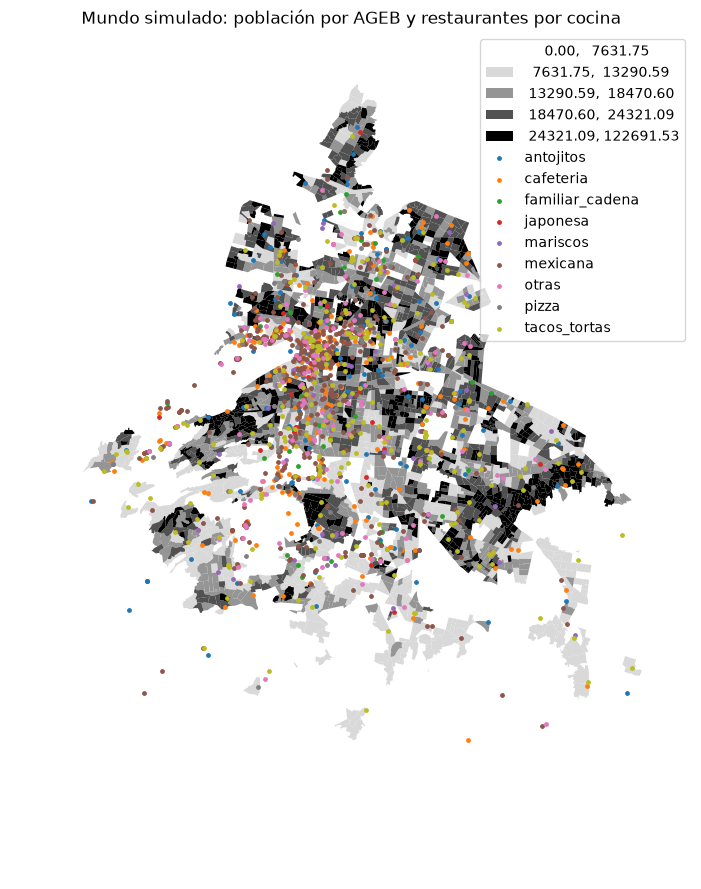

In [10]:
plot_world(ageb, restaurants, save_to=paths.figures / "01_mundo_cdmx.png");

## 8. Guardado

In [11]:
universe.drop(columns=["normalized_name"]).to_parquet(
    out_dir / "restaurants_universe.parquet", index=False
)
restaurants.to_parquet(out_dir / "restaurants.parquet", index=False)
ageb.to_parquet(out_dir / "ageb.parquet", index=False)
sorted(p.name for p in out_dir.iterdir())

['ageb.parquet', 'restaurants.parquet', 'restaurants_universe.parquet']

## Conclusiones

- **Universo real:** de los establecimientos SCIAN 7225 de la CDMX, ~8,200 cumplen el perfil de cliente de Puzzle (servicio en mesa y 6+ personas ocupadas).
- **Homologación:** las reglas etiquetan ~70 % del universo. El KNN supera ampliamente a la línea base de clase mayoritaria, pero cubre pocos casos: los nombres genéricos ("TENEDOR DEL CIELO") **no contienen señal de cocina**. Esos casos reciben el valor por defecto `mexicana`, un **supuesto declarado** (`docs/supuestos.md`, S3) coherente con el giro "a la carta o comida corrida".
- **La ubicación no ayuda a imputar la cocina** (empeora el F1 macro), por eso `geo_weight = 0`.
- **Pasa al notebook 02:** `restaurants.parquet` (con `cuisine_pred`) define qué platillos canónicos tendrá cada menú. **Pasa al 03:** `ageb.parquet` para ubicar a los comensales.